In [342]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/iammustafatz/diabetes-prediction-dataset/diabetes_prediction_dataset.csv
/kaggle/input/datasets/sagnikpatra/uci-adult-census-data-dataset/adult_test.csv
/kaggle/input/datasets/sagnikpatra/uci-adult-census-data-dataset/adult_train.csv
/kaggle/input/datasets/lovishbansal123/titanic-dataset/Titanic-Dataset.csv
/kaggle/input/datasets/shree1992/housedata/data.csv
/kaggle/input/datasets/shree1992/housedata/data.dat
/kaggle/input/datasets/shree1992/housedata/output.csv


In [343]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [344]:
uci = pd.read_csv('/kaggle/input/datasets/sagnikpatra/uci-adult-census-data-dataset/adult_train.csv')
diabetes = pd.read_csv('/kaggle/input/datasets/iammustafatz/diabetes-prediction-dataset/diabetes_prediction_dataset.csv')
titanic = pd.read_csv('/kaggle/input/datasets/lovishbansal123/titanic-dataset/Titanic-Dataset.csv')
house = pd.read_csv('/kaggle/input/datasets/shree1992/housedata/data.csv')

In [345]:
uci

,Age,Workclass,fnlwgt,Education,Education_Num,Martial_Status,Occupation,Relationship,Race,Sex,Capital_Gain,Capital_Loss,Hours_per_week,Country,Target
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [346]:
uci['Martial_Status'].value_counts()

Martial_Status
Married-civ-spouse       14976
Never-married            10683
Divorced                  4443
Separated                 1025
Widowed                    993
Married-spouse-absent      418
Married-AF-spouse           23
Name: count, dtype: int64

In [347]:
m = uci['Martial_Status'].unique()
m = m.tolist()
m

[' Never-married',
 ' Married-civ-spouse',
 ' Divorced',
 ' Married-spouse-absent',
 ' Separated',
 ' Married-AF-spouse',
 ' Widowed']

In [348]:
uci['Workclass'].value_counts()

Workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64

In [349]:
x = uci['Workclass'].unique()
x = x.tolist()
x

[' State-gov',
 ' Self-emp-not-inc',
 ' Private',
 ' Federal-gov',
 ' Local-gov',
 nan,
 ' Self-emp-inc',
 ' Without-pay',
 ' Never-worked']

# imputing categorical missing values

# 1. replacing with common value

In [350]:
uci.isnull().sum()

Age                  0
Workclass         1836
fnlwgt               0
Education            0
Education_Num        0
Martial_Status       0
Occupation        1843
Relationship         0
Race                 0
Sex                  0
Capital_Gain         0
Capital_Loss         0
Hours_per_week       0
Country            583
Target               0
dtype: int64

In [351]:
uci.isnull().mean()

Age               0.000000
Workclass         0.056386
fnlwgt            0.000000
Education         0.000000
Education_Num     0.000000
Martial_Status    0.000000
Occupation        0.056601
Relationship      0.000000
Race              0.000000
Sex               0.000000
Capital_Gain      0.000000
Capital_Loss      0.000000
Hours_per_week    0.000000
Country           0.017905
Target            0.000000
dtype: float64

In [352]:
# we will replace the missing workclass values with highest values
uci['Workclass'].value_counts()
# here the missing values will replace by the Private

Workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64

In [353]:
uci['Workclass'].isnull().sum()

np.int64(1836)

In [354]:
replaced_by = uci['Workclass'].mode()[0]
uci['Workclass'] = uci['Workclass'].fillna(replaced_by)
uci['Workclass'].isnull().sum()

np.int64(0)

# 2. remove the missing rows

In [355]:
uci.isnull().sum()

Age                  0
Workclass            0
fnlwgt               0
Education            0
Education_Num        0
Martial_Status       0
Occupation        1843
Relationship         0
Race                 0
Sex                  0
Capital_Gain         0
Capital_Loss         0
Hours_per_week       0
Country            583
Target               0
dtype: int64

In [356]:
uci = uci.dropna(subset = 'Country')
uci['Country'].isnull().sum()

np.int64(0)

In [357]:
# let's remove the occupation missing values
uci = uci.dropna(subset = 'Occupation')
uci['Occupation'].isnull().sum()

np.int64(0)

# Numerical missing values imputation

In [358]:
titanic

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [359]:
# finding the number of missing values
titanic.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [360]:
# finding the percentage of missing values
titanic.isnull().mean()

# here age has approximately 20% missing values

PassengerId    0.000000
Survived       0.000000
Pclass         0.000000
Name           0.000000
Sex            0.000000
Age            0.198653
SibSp          0.000000
Parch          0.000000
Ticket         0.000000
Fare           0.000000
Cabin          0.771044
Embarked       0.002245
dtype: float64

# simple imputation

<Axes: xlabel='Age', ylabel='Density'>

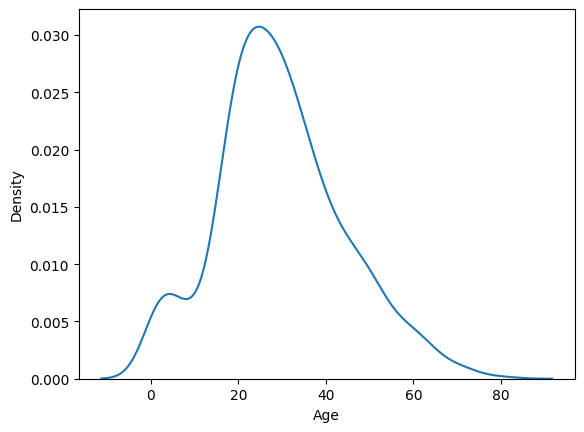

In [361]:
sns.kdeplot(data = titanic, x = 'Age')

In [362]:
# simple imputation replace the missing values with a specific value like mean, median

from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy = 'median')

titanic['Age_simple'] = imputer.fit_transform(titanic[['Age']])

print(titanic[['Age','Age_simple']].sample(20))

# here we have created a new column after imputing the missing cells to show a comparison with 
# actual column

       Age  Age_simple
775  18.00       18.00
578    NaN       28.00
112  22.00       22.00
315  26.00       26.00
200  28.00       28.00
801  31.00       31.00
88   23.00       23.00
730  29.00       29.00
8    27.00       27.00
312  26.00       26.00
295    NaN       28.00
193   3.00        3.00
754  48.00       48.00
574  16.00       16.00
323  22.00       22.00
286  30.00       30.00
102  21.00       21.00
594  37.00       37.00
469   0.75        0.75
404  20.00       20.00


<Axes: xlabel='Age', ylabel='Count'>

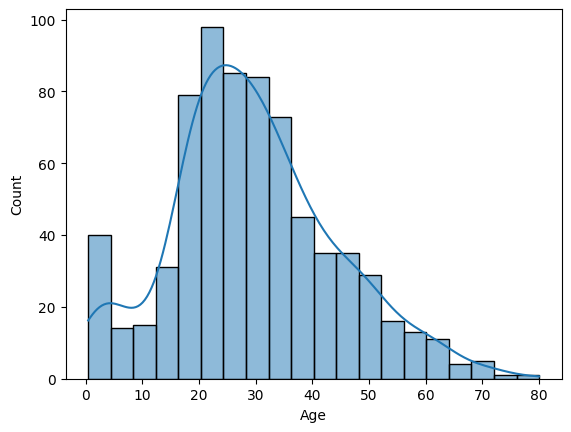

In [363]:
sns.histplot(data = titanic, x = 'Age', kde = True)

<Axes: xlabel='Age_simple', ylabel='Count'>

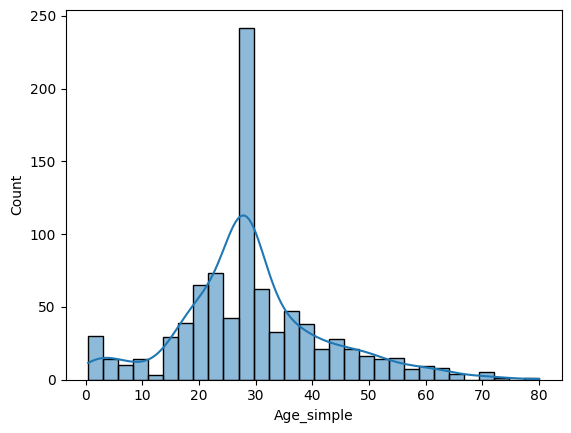

In [364]:
sns.histplot(data = titanic, x = 'Age_simple', kde = True)

# the main problem of simple imputaiton is the missing values replace with a specific value
# which dominates the training process

# KNN imputer

In [365]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
 12  Age_simple   891 non-null    float64
dtypes: float64(3), int64(5), object(5)
memory usage: 90.6+ KB


In [366]:
from sklearn.impute import KNNImputer

imputer = KNNImputer(n_neighbors = 5)

features = titanic[['Pclass','SibSp','Parch','Fare','Age']]

features_imputed = imputer.fit_transform(features)

# knn imputer replace missing values with a value related with other columns

In [367]:
titanic['Age_knn'] = features_imputed[:,4]
print(titanic[['Age','Age_knn']].sample(20))

      Age  Age_knn
46    NaN     28.8
738   NaN     30.2
800  34.0     34.0
94   59.0     59.0
844  17.0     17.0
282  16.0     16.0
164   1.0      1.0
760   NaN     27.2
747  30.0     30.0
482  50.0     50.0
609  40.0     40.0
89   24.0     24.0
5     NaN     24.8
879  56.0     56.0
97   23.0     23.0
201   NaN     37.0
351   NaN     49.4
19    NaN     30.5
516  34.0     34.0
606  30.0     30.0


<Axes: xlabel='Age_knn', ylabel='Count'>

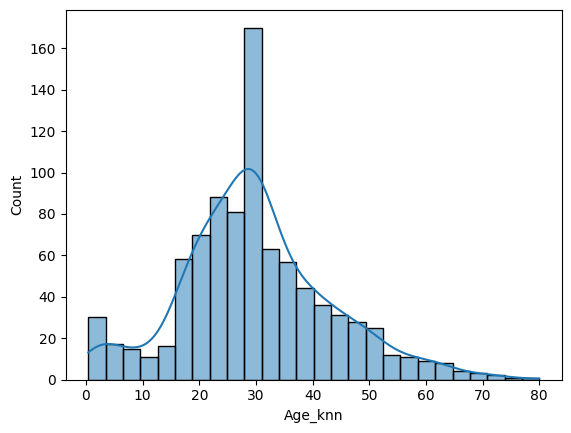

In [368]:
sns.histplot(data = titanic, x = 'Age_knn', kde = True)

# drop columns

In [369]:
titanic.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
Age_simple       0
Age_knn          0
dtype: int64

In [370]:
titanic

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Age_simple,Age_knn
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,22.0,22.0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,38.0,38.0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,26.0,26.0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,35.0,35.0
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,35.0,35.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S,27.0,27.0
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,19.0,19.0
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S,28.0,26.8
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,26.0,26.0


In [371]:
# here cabin has huge missing values, so we remove this
# passenger id has no impact on model training, so we remove this
# Name also don't need

tita_col_removed = titanic.drop(columns = ['PassengerId', 'Cabin', 'Name'])
tita_col_removed

,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Age_simple,Age_knn
0,0,3,male,22.0,1,0,A/5 21171,7.2500,S,22.0,22.0
1,1,1,female,38.0,1,0,PC 17599,71.2833,C,38.0,38.0
2,1,3,female,26.0,0,0,STON/O2. 3101282,7.9250,S,26.0,26.0
3,1,1,female,35.0,1,0,113803,53.1000,S,35.0,35.0
4,0,3,male,35.0,0,0,373450,8.0500,S,35.0,35.0
...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,211536,13.0000,S,27.0,27.0
887,1,1,female,19.0,0,0,112053,30.0000,S,19.0,19.0
888,0,3,female,NaN,1,2,W./C. 6607,23.4500,S,28.0,26.8
889,1,1,male,26.0,0,0,111369,30.0000,C,26.0,26.0


# Encoding

In [372]:
# a machine learning model don't understand the string values(male/female) of sex column, or
# character value of Embarked column, so we need to change them into numerical value

# 1. using mapping

In [373]:
titanic['Sex'] = titanic['Sex'].map({'male':0, 'female':1})
titanic['Sex']

# for small variation of data we use mapping

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    1
889    0
890    0
Name: Sex, Length: 891, dtype: int64

# 2. using label encoder

In [374]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

titanic['Embarked'] = encoder.fit_transform(titanic['Embarked'])

titanic['Embarked']

# we will use encoder when there are many variations on data

0      2
1      0
2      2
3      2
4      2
      ..
886    2
887    2
888    2
889    0
890    1
Name: Embarked, Length: 891, dtype: int64

# forward/backward fill

In [375]:
data = {
    'Student': ['A', 'B', 'C', 'D', 'E', 'F'],
    'Marks': [80, 75, np.nan, np.nan, 90, np.nan]
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df)

Original Dataset:
  Student  Marks
0       A   80.0
1       B   75.0
2       C    NaN
3       D    NaN
4       E   90.0
5       F    NaN


In [376]:
df['Marks'].ffill()
# replace the missing values with the values before the missing starting point

0    80.0
1    75.0
2    75.0
3    75.0
4    90.0
5    90.0
Name: Marks, dtype: float64

In [377]:
df['Marks'].bfill()
# replace the missing values with the values where the missing points ends

0    80.0
1    75.0
2    90.0
3    90.0
4    90.0
5     NaN
Name: Marks, dtype: float64

# outlier

# 1. Outlier detection and mitigation on normal distribution

In [378]:
titanic['Age']

0      22.0
1      38.0
2      26.0
3      35.0
4      35.0
       ... 
886    27.0
887    19.0
888     NaN
889    26.0
890    32.0
Name: Age, Length: 891, dtype: float64

In [379]:
titanic['Age'].skew()
# skewness is low, so the data is normally distributed

np.float64(0.38910778230082704)

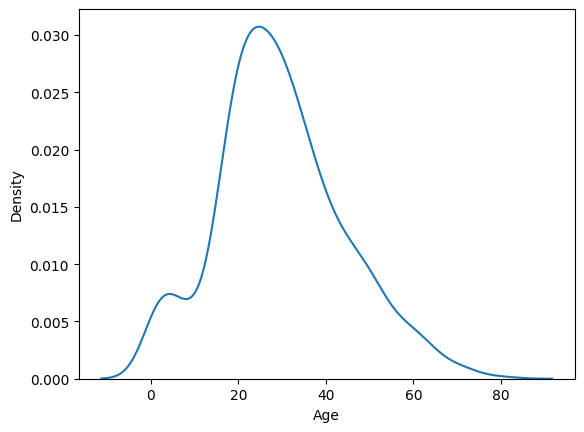

In [380]:
sns.kdeplot(data = titanic, x = 'Age')
plt.show()

In [381]:
# let's say we removed missing values
titanic = titanic.dropna(subset = 'Age')

In [382]:
titanic['Age'].skew()

np.float64(0.38910778230082693)

In [383]:
titanic['Age'].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

In [384]:
print("mean age",titanic['Age'].mean())
print("std",titanic['Age'].std())

mean age 29.69911764705882
std 14.526497332334044


In [385]:
print("highest allowed",titanic['Age'].mean() + 3* titanic['Age'].std())
x = titanic['Age'].mean() - 3* titanic['Age'].std()
print("lowest allowed",max(x,0))


highest allowed 73.27860964406095
lowest allowed 0


In [386]:
# select data who have age greater than upper limit and less than lower limit
titanic[(titanic['Age'] > 73.27) | (titanic['Age'] < 0)]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Age_simple,Age_knn
630,631,1,1,"Barkworth, Mr. Algernon Henry Wilson",0,80.0,0,0,27042,30.000,A23,2,80.0,80.0
851,852,0,3,"Svensson, Mr. Johan",0,74.0,0,0,347060,7.775,NaN,2,74.0,74.0


# 1. trimming/removal

In [387]:
titanic.shape

(714, 14)

In [388]:
new_tita = titanic[(titanic['Age'] < 73.27) & (titanic['Age'] > 0)]
new_tita

# taking the rows where age is less than upper limit and greater than lower limit

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Age_simple,Age_knn
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,NaN,2,22.0,22.0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,C85,0,38.0,38.0
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,NaN,2,26.0,26.0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,C123,2,35.0,35.0
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,NaN,2,35.0,35.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
885,886,0,3,"Rice, Mrs. William (Margaret Norton)",1,39.0,0,5,382652,29.1250,NaN,1,39.0,39.0
886,887,0,2,"Montvila, Rev. Juozas",0,27.0,0,0,211536,13.0000,NaN,2,27.0,27.0
887,888,1,1,"Graham, Miss. Margaret Edith",1,19.0,0,0,112053,30.0000,B42,2,19.0,19.0
889,890,1,1,"Behr, Mr. Karl Howell",0,26.0,0,0,111369,30.0000,C148,0,26.0,26.0


# 2. capping

In [389]:
Upper = titanic['Age'].mean() + 3* titanic['Age'].std()
lower = 0

In [390]:
titanic['Age'] = np.where(titanic['Age'] > Upper, Upper, 
        np.where(titanic['Age']<lower, lower, titanic['Age']))

/tmp/ipykernel_58/792864937.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  titanic['Age'] = np.where(titanic['Age'] > Upper, Upper,


In [391]:
titanic.shape

(714, 14)

In [392]:
titanic[(titanic['Age'] > 73.27) | (titanic['Age'] < 0)]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Age_simple,Age_knn
630,631,1,1,"Barkworth, Mr. Algernon Henry Wilson",0,73.27861,0,0,27042,30.000,A23,2,80.0,80.0
851,852,0,3,"Svensson, Mr. Johan",0,73.27861,0,0,347060,7.775,NaN,2,74.0,74.0


# 2. outlier detection and mitigation for skewed data

In [393]:
diabetes

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


<Axes: xlabel='bmi', ylabel='Density'>

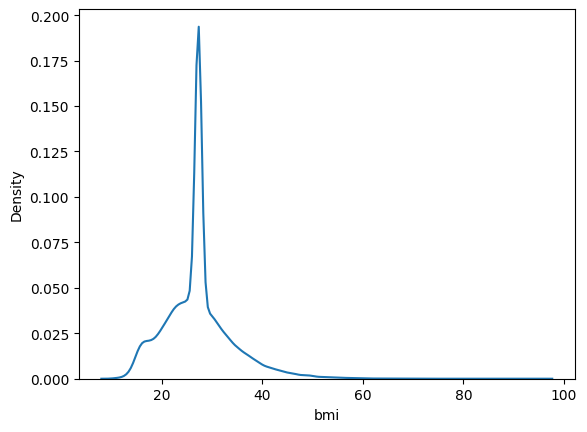

In [394]:
sns.kdeplot(data = diabetes, x = 'bmi')

In [395]:
diabetes['bmi']

0        25.19
1        27.32
2        27.32
3        23.45
4        20.14
         ...  
99995    27.32
99996    17.37
99997    27.83
99998    35.42
99999    22.43
Name: bmi, Length: 100000, dtype: float64

In [396]:
diabetes['bmi'].skew()

np.float64(1.0438355183081105)

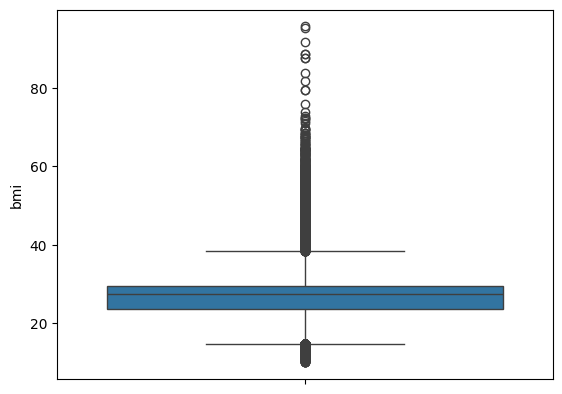

In [397]:
sns.boxplot(diabetes['bmi'])
plt.show()

In [398]:
diabetes['bmi'].describe()

count    100000.000000
mean         27.320767
std           6.636783
min          10.010000
25%          23.630000
50%          27.320000
75%          29.580000
max          95.690000
Name: bmi, dtype: float64

In [399]:
prec25 = diabetes['bmi'].quantile(0.25)
prec75 = diabetes['bmi'].quantile(0.75)

In [400]:
print("25th percentile, Q1: ",prec25)
print("75th percentile, Q3: ",prec75)

25th percentile, Q1:  23.63
75th percentile, Q3:  29.58


In [401]:
IQR = prec75 - prec25
IQR

np.float64(5.949999999999999)

In [402]:
upper_limit = prec75 + 1.5 * IQR
lower_limit = prec25 - 1.5 * IQR

In [403]:
print("Upper limit: ",upper_limit)
print("Lower limit: ",lower_limit)

Upper limit:  38.504999999999995
Lower limit:  14.705


In [404]:
# rows where bmi greater than upper limit
diabetes[diabetes['bmi'] > upper_limit]

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
11,Female,54.0,0,0,former,54.70,6.0,100,0
39,Female,34.0,0,0,never,56.43,6.2,200,0
59,Female,67.0,0,0,never,63.48,8.8,155,1
93,Male,38.0,0,0,never,55.61,6.5,130,0
98,Female,30.0,0,0,No Info,50.13,6.0,100,0
...,...,...,...,...,...,...,...,...,...
99892,Female,67.0,0,0,No Info,44.39,6.0,145,0
99948,Female,56.0,1,0,former,39.62,4.5,126,0
99953,Female,59.0,1,0,ever,60.52,3.5,158,0
99960,Female,47.0,0,0,former,45.15,4.0,126,0


In [405]:
# rows where bmi lower than lower limit
diabetes[diabetes['bmi'] < lower_limit]

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
24,Female,4.00,0,0,No Info,13.99,4.0,140,0
155,Female,0.08,0,0,No Info,14.43,6.5,160,0
221,Male,6.00,0,0,No Info,13.79,6.5,160,0
264,Female,4.00,0,0,No Info,13.57,3.5,126,0
268,Female,0.16,0,0,No Info,12.15,6.6,100,0
...,...,...,...,...,...,...,...,...,...
99778,Female,0.32,0,0,No Info,12.26,5.8,126,0
99825,Male,7.00,0,0,No Info,14.66,5.8,158,0
99841,Female,9.00,0,0,No Info,14.13,6.5,200,0
99906,Male,3.00,0,0,No Info,14.21,6.6,145,0


# 1. trimming

In [406]:
diabetes.shape

(100000, 9)

In [407]:
# the outliers are removed
new_dia = diabetes[(diabetes['bmi'] < upper_limit) & (diabetes['bmi'] > lower_limit)]
new_dia.shape

(92914, 9)

# 2. capping

In [408]:
new_df_cap = diabetes.copy()
# upper outliers are replaced by upper limit and lower outlier replaced with lower limit
new_df_cap['bmi'] = np.where(new_df_cap['bmi'] > upper_limit, upper_limit,
                            np.where(new_df_cap['bmi']< lower_limit, lower_limit, new_df_cap['bmi']))

In [409]:
new_df_cap.shape

(100000, 9)

<Axes: ylabel='bmi'>

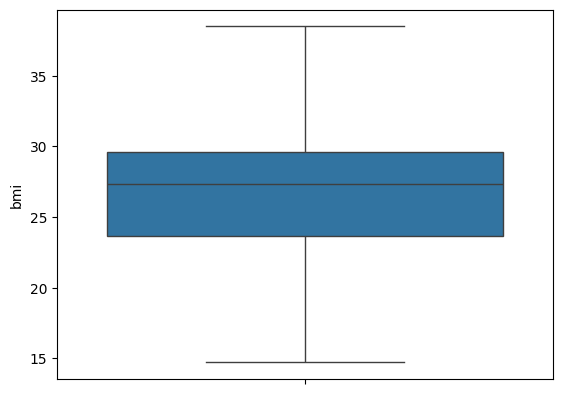

In [410]:
sns.boxplot(new_df_cap['bmi'])

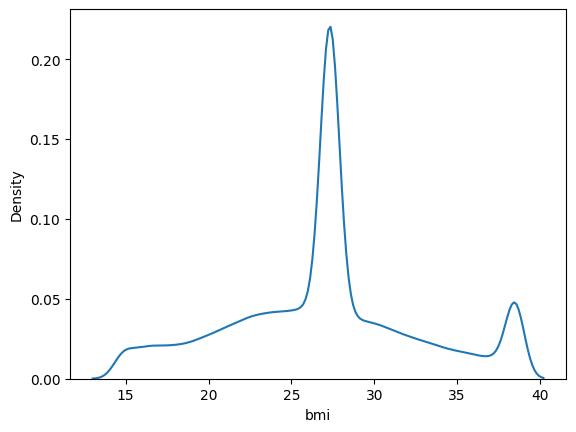

In [411]:
sns.kdeplot(data = new_df_cap, x = 'bmi')
plt.show()

# Data type conversion

In [412]:
import pandas as pd

data = {
    "Name": [
        "  John Smith",
        "MARY JOHNSON  ",
        "Robert@Brown",
        "  alice smith  ",
        "David Jones!!!",
        "SARAH WILSON"
    ],
    "Email": [
        "john@gmail.com",
        " MARY@YAHOO.COM ",
        "robert@gmail.com",
        "alice@gmail.com",
        "david@outlook.com",
        "sarah@gmail.com"
    ],
    "City": [
        "New York",
        "new york",
        " NEW YORK ",
        "London",
        "london ",
        "LONDON"
    ],
    "Job": [
        " Data Scientist ",
        "data scientist",
        "DATA SCIENTIST",
        "Software Engineer",
        "?",
        " software engineer "
    ],
    "Age": [25, 30, 28, 35, 40, 29]
}

df = pd.DataFrame(data)

print(df)

              Name              Email        City                  Job  Age
0       John Smith     john@gmail.com    New York      Data Scientist    25
1   MARY JOHNSON      MARY@YAHOO.COM     new york       data scientist   30
2     Robert@Brown   robert@gmail.com   NEW YORK        DATA SCIENTIST   28
3    alice smith      alice@gmail.com      London    Software Engineer   35
4   David Jones!!!  david@outlook.com     london                     ?   40
5     SARAH WILSON    sarah@gmail.com      LONDON   software engineer    29


# some very common operations

In [413]:
# remove spaces
df["Name"] = df["Name"].str.strip()
df['Name']

0        John Smith
1      MARY JOHNSON
2      Robert@Brown
3       alice smith
4    David Jones!!!
5      SARAH WILSON
Name: Name, dtype: object

In [414]:
# convert into lowercase
df["City"] = df["City"].str.lower()
df["City"]

0      new york
1      new york
2     new york 
3        london
4       london 
5        london
Name: City, dtype: object

In [415]:
# remove special characters
df["Name"] = df["Name"].str.replace(r"[^\w\s]", "", regex=True)
df["Name"]

0      John Smith
1    MARY JOHNSON
2     RobertBrown
3     alice smith
4     David Jones
5    SARAH WILSON
Name: Name, dtype: object

In [416]:
# replace missing positions
df["Job"] = df["Job"].replace("?", pd.NA)
df["Job"]

0        Data Scientist 
1         data scientist
2         DATA SCIENTIST
3      Software Engineer
4                   <NA>
5     software engineer 
Name: Job, dtype: object

In [417]:
# find values which contains a specifit word
df[df["Job"].str.contains("data", case=False, na=False)]

,Name,Email,City,Job,Age
0,John Smith,john@gmail.com,new york,Data Scientist,25
1,MARY JOHNSON,MARY@YAHOO.COM,new york,data scientist,30
2,RobertBrown,robert@gmail.com,new york,DATA SCIENTIST,28


In [418]:
# check string length
df["Name_Length"] = df["Name"].str.len()
df["Name_Length"]

0    10
1    12
2    11
3    11
4    11
5    12
Name: Name_Length, dtype: int64

In [419]:
# extract email domain
df["Email_Domain"] = df["Email"].str.split("@").str[-1]
df["Email_Domain"]

0      gmail.com
1     YAHOO.COM 
2      gmail.com
3      gmail.com
4    outlook.com
5      gmail.com
Name: Email_Domain, dtype: object

In [420]:
# remove multiple spaces
df["Name"] = df["Name"].str.replace(r"\s+", " ", regex=True)
df["Name"]

0      John Smith
1    MARY JOHNSON
2     RobertBrown
3     alice smith
4     David Jones
5    SARAH WILSON
Name: Name, dtype: object

# duplicate operations

In [421]:
# duplicate operations
data = {
    'Student_ID': [101, 102, 103, 103, 104, 105, 105],
    'Name': ['Rahim', 'Karim', 'Sakib', 'Sakib', 'Nila', 'Hasan', 'Hasan'],
    'Age': [20, 21, 19, 19, 22, 20, 20],
    'Marks': [85, 78, 92, 92, 88, 75, 75]
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df)


Original Dataset:
   Student_ID   Name  Age  Marks
0         101  Rahim   20     85
1         102  Karim   21     78
2         103  Sakib   19     92
3         103  Sakib   19     92
4         104   Nila   22     88
5         105  Hasan   20     75
6         105  Hasan   20     75


In [422]:
# Check for duplicate rows
print(df[df.duplicated()])
print("number of duplicates",df.duplicated().sum())
# print(df[df.duplicated()])

   Student_ID   Name  Age  Marks
3         103  Sakib   19     92
6         105  Hasan   20     75
number of duplicates 2


In [423]:
# Remove duplicate rows
df_cleaned = df.drop_duplicates()
df_cleaned

,Student_ID,Name,Age,Marks
0,101,Rahim,20,85
1,102,Karim,21,78
2,103,Sakib,19,92
4,104,Nila,22,88
5,105,Hasan,20,75
